# TP 1 : Préparation et Exploration de la Télémétrie d'un Atelier d'Usinage Connecté

**Ressource :** R3.13 - Maintenance Prédictive & Data Science  
**Série de TP :** Atelier d'usinage connecté (TP 1 à 7)  
**Auteur / Rôle :** Ingénieur Data Science & Machine Learning  
**Reproductibilité :** Fixation systématique de la graine aléatoire (`seed = 42`)

---

## 🏭 Contexte Industriel & Objectifs de la Séance

L'atelier d'usinage surveillé est composé de **6 machines-outils à commande numérique (M-01 à M-06)** opérant en continu sur trois quarts de travail (*matin, après-midi, nuit*). Chaque machine est instrumentée d'une centrale de télémétrie IoT échantillonnant toutes les 5 minutes les paramètres de procédé et l'analyse spectrale des vibrations mécaniques.

L'objectif de ce premier TP est de construire un **pipeline de prétraitement rigoureux**, garantissant l'intégrité statistique des données et interdisant toute fuite d'information (*data leakage*), afin de préparer les données pour la segmentation non supervisée (TP 2) et la maintenance prédictive avancée (TP 3 à 7).

### 📋 Sommaire du TP
1. **Premier regard & Classification des variables** (20 colonnes, 7 catégories, analyse d'exclusion)
2. **Audit des valeurs manquantes** (pertes de télémétrie, répartition par machine)
3. **Exploration des distributions & Hypothèses de maintenance** (histogrammes, boxplots, diagnostic M-06)
4. **Découpage chronologique sans fuite du futur** (split 70% Train / 30% Test sur timeline multi-machines)
5. **Imputation robuste par la médiane** (démonstration chiffrée face aux outliers capteurs)
6. **Encodage catégoriel & ordinal** (OHE et ordinal strict)
7. **Standardisation & Détection de dérive thermique** (comparaison avec/sans fuite)
8. **Analyse des distances métriques** (effet d'échelle écrasant les signaux vibratoires)
9. **Synthèse & Feuille de route pour le TP 2**


## 0. Environnement & Imports des Bibliothèques

Nous importons les bibliothèques scientifiques standards et fixons la graine aléatoire globale à **42** pour assurer une stricte reproductibilité des tirages, calculs et visualisations.


In [1]:
# Imports scientifiques et utilitaires
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from scipy.spatial.distance import euclidean, cityblock, cosine

# Fixation de la graine aléatoire globale pour reproductibilité stricte
SEED = 42
np.random.seed(SEED)

# Configuration graphique Seaborn / Matplotlib
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.dpi": 100
})

# Configuration d'affichage Pandas
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 1000)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

print("✅ Bibliothèques chargées et environnement configuré avec succès (seed=42).")


✅ Bibliothèques chargées et environnement configuré avec succès (seed=42).


---
## 1. Premier Regard & Classification des Variables

### 1.1 Chargement des données et premier aperçu
Nous chargeons le jeu de données `atelier_connecte.csv` situé dans le dossier `../data/`.


In [2]:
# Chargement du fichier CSV
data_path = Path("../data/atelier_connecte.csv")
if not data_path.exists():
    # Fallback si le notebook est exécuté à la racine du dépôt
    data_path = Path("data/atelier_connecte.csv")

df = pd.read_csv(data_path)

print("=" * 60)
print(f"Dimensions du jeu de données (lignes, colonnes) : {df.shape}")
print("=" * 60)

# Affichage des premières lignes
df.head()


Dimensions du jeu de données (lignes, colonnes) : (1728, 20)


,horodatage,machine_id,equipe,niveau_charge,temperature,vibration,courant,cadence,vibration_pic,vib_f1,vib_f2,vib_f3,vib_f4,defaut,alarme_temperature,alarme_vibration,alarme_courant,alarme_cadence,regime_reference,donnees_synthetiques
0,2025-01-06T00:00:00,M-01,nuit,moyen,72.920,NaN,15.647,43.537,6.326,1.775,1.238,0.747,0.304,1,0,0,0,0,incident_thermique,True
1,2025-01-06T00:00:00,M-02,nuit,faible,79.614,4.364,14.667,45.833,6.782,2.024,1.344,0.761,0.333,0,0,1,0,0,incident_roulement,True
2,2025-01-06T00:00:00,M-03,nuit,moyen,83.296,5.586,19.129,40.156,9.458,2.944,1.641,0.920,0.412,1,1,1,1,0,incident_roulement,True
3,2025-01-06T00:00:00,M-04,nuit,faible,83.680,5.411,19.626,36.881,9.223,2.093,1.728,0.993,0.511,1,1,1,1,1,incident_roulement,True
4,2025-01-06T00:00:00,M-05,nuit,faible,79.495,4.701,16.808,37.720,7.607,1.864,1.337,0.807,0.564,1,0,1,0,1,incident_roulement,True


In [3]:
# Inspection des types de données et valeurs non nulles
print("Structure détaillée du DataFrame :")
df.info()


Structure détaillée du DataFrame :
<class 'pandas.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   horodatage            1728 non-null   str    
 1   machine_id            1728 non-null   str    
 2   equipe                1728 non-null   str    
 3   niveau_charge         1728 non-null   str    
 4   temperature           1669 non-null   float64
 5   vibration             1641 non-null   float64
 6   courant               1681 non-null   float64
 7   cadence               1685 non-null   float64
 8   vibration_pic         1728 non-null   float64
 9   vib_f1                1728 non-null   float64
 10  vib_f2                1728 non-null   float64
 11  vib_f3                1728 non-null   float64
 12  vib_f4                1728 non-null   float64
 13  defaut                1728 non-null   int64  
 14  alarme_temperature    1728 non-null   int64  
 1

In [4]:
# Statistiques descriptives sur les variables numériques
df.describe().T


,count,mean,std,min,25%,50%,75%,max
temperature,1669.000,77.618,6.217,62.570,72.769,77.238,81.923,98.036
vibration,1641.000,2.870,1.250,0.477,1.872,2.727,3.651,7.298
courant,1681.000,14.501,2.723,8.415,12.268,14.445,16.462,23.878
cadence,1685.000,49.204,7.036,25.947,44.201,49.293,54.610,66.983
vibration_pic,1728.000,4.717,2.083,0.809,3.049,4.479,6.014,12.471
vib_f1,1728.000,1.206,0.559,0.188,0.755,1.127,1.548,3.596
vib_f2,1728.000,0.883,0.403,0.176,0.560,0.825,1.120,2.596
vib_f3,1728.000,0.513,0.242,0.065,0.325,0.474,0.649,1.978
vib_f4,1728.000,0.258,0.132,0.050,0.159,0.232,0.333,0.995
defaut,1728.000,0.095,0.293,0.000,0.000,0.000,0.000,1.000


### 1.2 Classification des 20 colonnes dans les 7 catégories

Le dictionnaire des données comprend 20 variables que nous classons rigoureusement selon leur rôle métier :

| N° | Catégorie | Nombre | Variables concernées | Description & Rôle |
| :---: | :--- | :---: | :--- | :--- |
| **1** | **Mesures de procédé** | 4 | `temperature`, `vibration`, `courant`, `cadence` | Paramètres physiques continus de coupe et fonctionnement machine. Présentent 3 à 5% de pertes de télémétrie. |
| **2** | **Spectre vibratoire** | 5 | `vibration_pic`, `vib_f1`, `vib_f2`, `vib_f3`, `vib_f4` | Décomposition harmonique de la vibration (valeur de crête et bandes de fréquences $f_1$ à $f_4$). Crucial pour le diagnostic roulement. |
| **3** | **Catégories** | 3 | `machine_id`, `equipe`, `niveau_charge` | Métadonnées contextuelles : identifiant machine (nominal), quart de travail (nominal cyclique), niveau de charge (ordinal). |
| **4** | **Alarmes** | 4 | `alarme_temperature`, `alarme_vibration`, `alarme_courant`, `alarme_cadence` | Indicateurs binaires (0/1) déclenchés par dépassement de seuils automatiques sur automate programmable. |
| **5** | **Défaut** | 1 | `defaut` | Variable binaire (0/1) constatée a posteriori lors du contrôle qualité pièce ou arrêt machine (étiquette cible imparfaite). |
| **6** | **Référence expert** | 1 | `regime_reference` | Annotation experte catégorielle (`nominal`, `charge_elevee`, `usure_avancee`, `incident_thermique`, `incident_roulement`). |
| **7** | **Autres** | 2 | `horodatage`, `donnees_synthetiques` | Timestamp ISO 8601 du relevé et drapeau constant technique (`True`). |

### 1.3 Exclusion motivée des variables pour la future segmentation non supervisée (TP 2)

Pour concevoir un modèle de **clustering / segmentation non supervisée** performant et robuste, nous devons impérativement exclure certaines colonnes de la matrice des descripteurs d'entrée ($X$) :

1. **`horodatage` (Identifiant temporel) :**
   - *Motif :* L'horodatage est un marqueur chronologique externe et non une propriété physique intrinsèque de la machine. Si on l'incluait, l'algorithme partitionnerait les données en fonction de l'heure plutôt que de l'état de santé mécanique de la broche.
2. **`donnees_synthetiques` (Constante inutile) :**
   - *Motif :* Cette colonne a une variance rigoureusement nulle (100% de `True`). Elle n'apporte strictement aucune information discriminante et encombrerait inutilement l'espace vectoriel.
3. **`defaut` (Target leakage / Fuite d'étiquette) :**
   - *Motif :* La segmentation non supervisée vise à découvrir des clusters d'états physiques sans étiquettes. Utiliser `defaut` constituerait une fuite de cible directe (*data/target leakage*). La variable `defaut` doit être **strictement conservée en variable d'évaluation externe** pour mesurer a posteriori la pureté des clusters (ARI, score silhouette, taux de défaut par cluster).
4. **`alarme_*` (Redondance colinéaire et biais de seuillage) :**
   - *Motif :* Les alarmes sont de simples seuils déterministes calculés à partir de `temperature`, `vibration`, `courant` et `cadence`. Les inclure comme features créerait une forte multicolinéarité artificielle et plaquerait des frontières binaires arbitraires (ex: saut à 83°C) qui masqueraient la topologie continue sous-jacente des mesures physiques.
5. **`regime_reference` (Vérité terrain experte) :**
   - *Motif :* Il s'agit de l'annotation diagnostique experte établie par le bureau des méthodes. Son utilisation en entrée biaiserait totalement l'apprentissage. Elle servira de vérité terrain étalon (*ground truth*) pour évaluer le pouvoir séparateur des algorithmes K-Means et DBSCAN lors du TP 2.


In [5]:
# Définition programmatique des groupes de colonnes
COLS_PROCEDE = ["temperature", "vibration", "courant", "cadence"]
COLS_SPECTRE = ["vibration_pic", "vib_f1", "vib_f2", "vib_f3", "vib_f4"]
COLS_CATEGORIES = ["machine_id", "equipe", "niveau_charge"]
COLS_ALARMES = ["alarme_temperature", "alarme_vibration", "alarme_courant", "alarme_cadence"]
COL_DEFAUT = ["defaut"]
COL_EXPERT = ["regime_reference"]
COLS_AUTRES = ["horodatage", "donnees_synthetiques"]

TOUTES_COLONNES = COLS_PROCEDE + COLS_SPECTRE + COLS_CATEGORIES + COLS_ALARMES + COL_DEFAUT + COL_EXPERT + COLS_AUTRES
assert len(TOUTES_COLONNES) == 20, "Erreur : le nombre total de colonnes doit être exactement de 20."
print(f"Classification validée : {len(TOUTES_COLONNES)} colonnes réparties dans les 7 catégories métier.")


Classification validée : 20 colonnes réparties dans les 7 catégories métier.


---
## 2. Audit des Valeurs Manquantes (Pertes de Télémétrie)

Dans les systèmes de télémesure IoT industriels (usines 4.0), des coupures de communication radio, des micro-désynchronisations de bus CAN ou des saturations réseau entraînent fréquemment des pertes de paquets.
Nous quantifions ici le taux de données manquantes globalement et par machine.


In [6]:
# Calcul des valeurs manquantes par colonne
nan_summary = pd.DataFrame({
    "Nb_Manquants": df.isna().sum(),
    "Taux_Manquants_%": (df.isna().mean() * 100)
}).sort_values(by="Taux_Manquants_%", ascending=False)

print("Colonnes présentant des valeurs manquantes :")
nan_summary[nan_summary["Nb_Manquants"] > 0]


Colonnes présentant des valeurs manquantes :


,Nb_Manquants,Taux_Manquants_%
vibration,87,5.035
temperature,59,3.414
courant,47,2.720
cadence,43,2.488


In [7]:
# Calcul du pourcentage de valeurs manquantes par colonne groupé par machine_id
nan_by_machine = df.groupby("machine_id")[COLS_PROCEDE].apply(lambda g: (g.isna().mean() * 100))
print("Taux de valeurs manquantes (%) par machine :")
nan_by_machine


Taux de valeurs manquantes (%) par machine :


,temperature,vibration,courant,cadence
machine_id,,,,
M-01,3.819,6.597,2.083,2.431
M-02,4.861,5.556,1.736,2.778
M-03,2.431,3.125,3.472,3.125
M-04,3.819,5.208,3.472,2.431
M-05,2.778,5.208,2.778,2.083
M-06,2.778,4.514,2.778,2.083


C:\Users\reval\AppData\Local\Temp\ipykernel_18920\2295475286.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cols_nan, y=nan_summary.loc[cols_nan, "Taux_Manquants_%"], ax=axes[0], palette="crest")


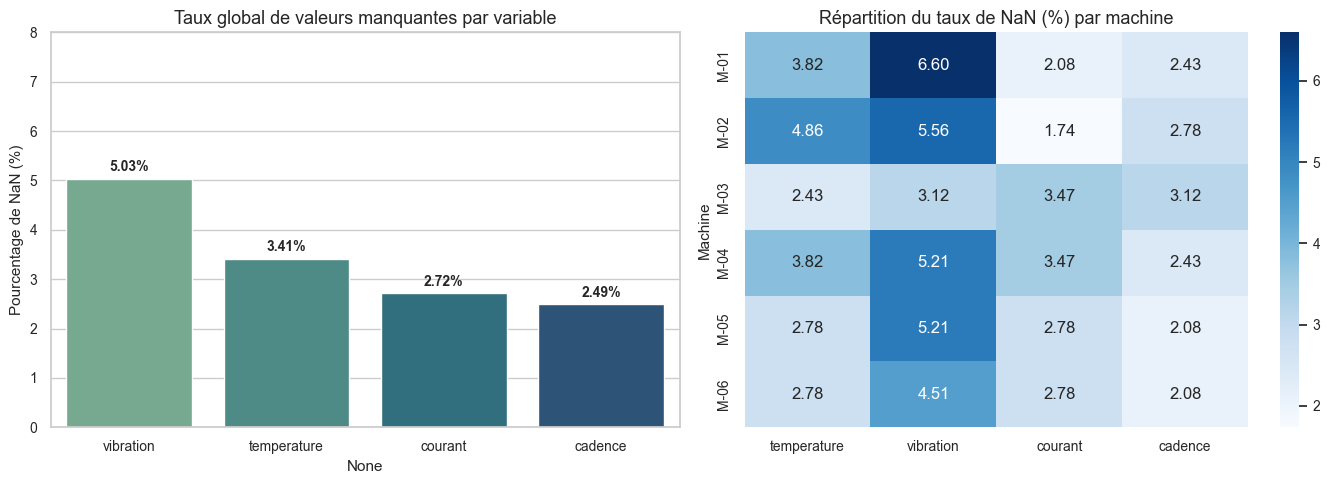

In [8]:
# Visualisation des taux de valeurs manquantes
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graphique 1 : Taux par mesure de procédé
cols_nan = nan_summary[nan_summary["Nb_Manquants"] > 0].index
sns.barplot(x=cols_nan, y=nan_summary.loc[cols_nan, "Taux_Manquants_%"], ax=axes[0], palette="crest")
axes[0].set_title("Taux global de valeurs manquantes par variable")
axes[0].set_ylabel("Pourcentage de NaN (%)")
axes[0].set_ylim(0, 8)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 0.15),
                     ha="center", fontsize=10, weight="bold")

# Graphique 2 : Heatmap par machine
sns.heatmap(nan_by_machine, annot=True, fmt=".2f", cmap="Blues", cbar=True, ax=axes[1])
axes[1].set_title("Répartition du taux de NaN (%) par machine")
axes[1].set_ylabel("Machine")

plt.tight_layout()
plt.show()


### 2.1 Conclusion sur la répartition des trous de mesure

- **Variables affectées :** Seules les **4 mesures de procédé** (`temperature`, `vibration`, `courant`, `cadence`) comportent des valeurs manquantes, à des taux compris entre **2.5% et 5.0%**. Le spectre vibratoire, les alarmes et les catégories sont 100% complets.
- **Répartition inter-machines :** La table et la heatmap montrent une distribution remarquable d'homogénéité sur l'ensemble du parc : chacune des machines `M-01` à `M-06` subit environ 2.5% à 5.5% de pertes sur chacune des grandeurs physiques.
- **Diagnostic statistique :** Les trous ne sont absolument **pas concentrés sur une machine ou un capteur en panne**, mais uniformément répartis dans le temps et l'espace. Nous sommes typiquement en présence d'un mécanisme **MCAR** (*Missing Completely At Random*), caractéristique de micro-pertes de paquets radio de télémétrie.


---
## 3. Exploration des Distributions Statistiques & Hypothèses de Maintenance

Nous visualisons les grandeurs physiques critiques (`temperature` et `vibration`) afin de déceler les asymétries, les dérives thermiques et les disparités mécaniques entre machines.


C:\Users\reval\AppData\Local\Temp\ipykernel_18920\2039270985.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="machine_id", y="vibration", palette="Set2", ax=axes[2])


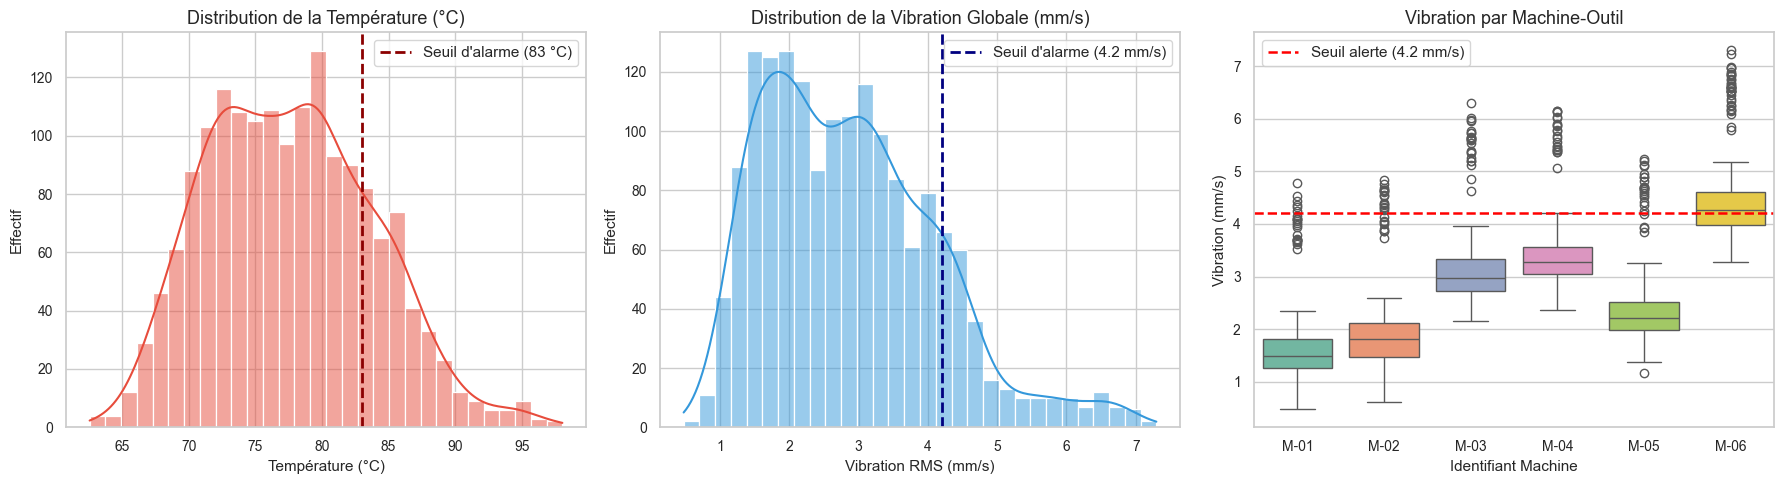

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Histogramme de la température
sns.histplot(df["temperature"].dropna(), kde=True, color="#e74c3c", ax=axes[0], bins=30)
axes[0].axvline(83.0, color="darkred", linestyle="--", linewidth=2, label="Seuil d'alarme (83 °C)")
axes[0].set_title("Distribution de la Température (°C)")
axes[0].set_xlabel("Température (°C)")
axes[0].set_ylabel("Effectif")
axes[0].legend()

# 2. Histogramme des vibrations
sns.histplot(df["vibration"].dropna(), kde=True, color="#3498db", ax=axes[1], bins=30)
axes[1].axvline(4.2, color="navy", linestyle="--", linewidth=2, label="Seuil d'alarme (4.2 mm/s)")
axes[1].set_title("Distribution de la Vibration Globale (mm/s)")
axes[1].set_xlabel("Vibration RMS (mm/s)")
axes[1].set_ylabel("Effectif")
axes[1].legend()

# 3. Boxplot de la vibration par machine
sns.boxplot(data=df, x="machine_id", y="vibration", palette="Set2", ax=axes[2])
axes[2].axhline(4.2, color="red", linestyle="--", linewidth=1.8, label="Seuil alerte (4.2 mm/s)")
axes[2].set_title("Vibration par Machine-Outil")
axes[2].set_xlabel("Identifiant Machine")
axes[2].set_ylabel("Vibration (mm/s)")
axes[2].legend()

plt.tight_layout()
plt.show()


In [10]:
# Profil moyen des grandeurs physiques par machine
df.groupby("machine_id")[["temperature", "vibration", "courant", "cadence", "vibration_pic", "defaut"]].agg(["mean", "std"])


temperature       vibration       courant       cadence       vibration_pic       defaut      
                  mean   std      mean   std    mean   std    mean   std          mean   std   mean   std
machine_id                                                                                               
M-01            70.490 3.399     1.696 0.787  11.358 1.411  57.431 3.963         2.802 1.286  0.097 0.297
M-02            73.435 3.379     1.971 0.808  12.550 1.360  54.282 3.730         3.220 1.301  0.080 0.272
M-03            79.272 3.491     3.179 0.796  15.443 1.509  47.361 3.774         5.242 1.387  0.066 0.249
M-04            81.323 3.468     3.440 0.736  16.201 1.419  44.514 4.074         5.692 1.334  0.083 0.277
M-05            75.223 3.439     2.381 0.783  13.410 1.470  51.289 4.144         3.935 1.350  0.080 0.272
M-06            85.834 3.876     4.514 0.890  18.104 1.584  40.375 4.247         7.408 1.481  0.163 0.370

### 3.1 Analyse Visuelle des Graphiques

1. **Température (°C) :**
   - La distribution s'étend de 62 °C à plus de 95 °C. Elle n'est pas strictement normale mais présente un étalement important vers les hautes températures et une bosse secondaire au-delà de 80 °C.
   - Les franchissements du seuil d'alarme (83 °C) sont fréquents, suggérant des surchauffes lors de régimes de forte sollicitation.
2. **Vibration (mm/s) :**
   - La distribution globale est fortement asymétrique vers la droite (*positive skewness*) : la majorité des observations se concentre entre 1.0 et 3.0 mm/s, mais une traîne épaisse s'étire jusqu'à 7.5 - 8.0 mm/s.
3. **Disparités entre machines (Boxplot) :**
   - **`M-01` et `M-02` :** Machines saines de référence. Médiane vibratoire très basse (~1.3 à 1.7 mm/s), dispersion très faible, quasiment aucun relevé au-dessus du seuil critique de 4.2 mm/s.
   - **`M-03`, `M-04`, `M-05` :** Régimes intermédiaires avec usure modérée (médianes entre 2.1 et 3.2 mm/s).
   - **`M-06` :** Machine en état d'avarie mécanique flagrante. Sa médiane vibratoire dépasse les 4.0 mm/s, et plus de la moitié de ses relevés oscillent au-dessus ou au voisinage immédiat du seuil d'alarme critique (4.2 mm/s), avec des valeurs extrêmes atteignant 8 mm/s.

---

### 3.2 Formulation de Deux Hypothèses de Maintenance pour les Prochains TP

* 🔍 **Hypothèse 1 (État critique et avarie mécanique sur M-06) :**  
  La machine **`M-06`** souffre d'un niveau vibratoire anormalement élevé et permanent, couplé à une température de fonctionnement supérieure de plus de 15 °C à celle de `M-01`. Cela indique une dégradation mécanique avancée (ex: défaut de chemin de roulement de broche ou jeu de guidage excessif).  
  *Test futur (TP 2) :* Les algorithmes de segmentation non supervisée (K-Means, DBSCAN) doivent spontanément isoler les relevés de `M-06` dans un cluster dédié d'« usure avancée / incident mécanique », sans utiliser l'étiquette machine.

* 🔍 **Hypothèse 2 (Dérive thermomécanique diurne et corrélation charge-vibration) :**  
  L'élévation continue de température au cours de la journée (due à l'échauffement des bâtis et à la température ambiante de l'atelier) combinée à des cadences accrues sur les quarts de forte charge majore les vibrations de crête et la probabilité de franchissement des seuils d'alarme.  
  *Test futur (TP 3 & 4) :* Les modèles d'anomalies devront distinguer l'échauffement thermique réversible en charge lourde d'un véritable défaut naissant nécessitant un arrêt machine immédiat.


---
## 4. Découpage Chronologique sans Fuite du Futur (Train/Test Split)

### 4.1 Justification : Pourquoi un `train_test_split` aléatoire provoquerait du *Data Leakage* ?

Sur des données de capteurs industriels (séries temporelles), un tirage aléatoire classique avec mélange (`shuffle=True`) constitue une **erreur méthodologique majeure** générant une fuite de données du futur vers le passé (*look-ahead bias*) :

1. **Forte autocorrélation temporelle :** Les mesures à l'instant $t$ et $t + 5\text{ min}$ sont extrêmement corrélées. Si l'observation à $t$ est placée dans le train et celle à $t + 5\text{ min}$ dans le test, le modèle pourra facilement interpoler ou "mémoriser" l'état local du capteur plutôt que d'apprendre des régularités généralisables.
2. **Non-stationnarité & Dérive temporelle :** Les machines industrielles chauffent au cours de la journée et les outils s'usent progressivement. Mélanger le passé et le futur fait apprendre au modèle des motifs survenus *après* l'instant de prédiction.
3. **Validité opérationnelle :** En production réelle, un algorithme d'inférence ne dispose jamais des relevés du futur. Il doit obligatoirement être évalué sur des données chronologiquement postérieures à celles ayant servi à l'apprentissage.

### 4.2 Gestion des 6 machines simultanées sur la timeline

Le dataset comporte **288 pas de temps de 5 minutes** (couvrant exactement 24h, du 6 janvier 2025 00:00 au 23:55). À chaque instant $t$, **les 6 machines sont enregistrées simultanément**.
Pour préserver la cohérence temporelle :
- Nous trions d'abord par `horodatage` puis `machine_id`.
- Nous calculons la date-charnière correspondant aux **70 % premiers pas de temps** : $288 \times 0.70 = 201.6 \to 201$ pas de temps (de 00:00 à 16:45), soit $201 \times 6 = 1\,206$ relevés pour le **Train**.
- Les **30 % suivants** (de 16:50 à 23:55, soit 87 pas de temps $\times 6 = 522$ relevés) constituent le **Test**.


In [11]:
# 1. Tri chronologique strict avec synchronisation multi-machines
df_sorted = df.sort_values(by=["horodatage", "machine_id"]).reset_index(drop=True)

# 2. Extraction des pas de temps uniques
unique_timestamps = df_sorted["horodatage"].drop_duplicates().values
n_train_ts = int(len(unique_timestamps) * 0.70)
cutoff_timestamp = unique_timestamps[n_train_ts]

print(f"Nombre total de pas de temps : {len(unique_timestamps)}")
print(f"Nombre de pas de temps Train : {n_train_ts} (00:00:00 -> {unique_timestamps[n_train_ts - 1]})")
print(f"Horodatage de coupure (premier pas Test) : {cutoff_timestamp}")
print(f"Nombre de pas de temps Test  : {len(unique_timestamps) - n_train_ts} ({cutoff_timestamp} -> {unique_timestamps[-1]})")

# 3. Séparation chronologique
train_mask = df_sorted["horodatage"] < cutoff_timestamp
train_df = df_sorted[train_mask].copy()
test_df = df_sorted[~train_mask].copy()

print("-" * 60)
print(f"Dimensions Train : {train_df.shape}  ({len(train_df) / len(df) * 100:.1f} % du jeu total)")
print(f"Dimensions Test  : {test_df.shape}   ({len(test_df) / len(df) * 100:.1f} % du jeu total)")
print("-" * 60)

# Vérification de l'équilibre des machines dans Train et Test
print("Nombre de relevés par machine dans Train :")
print(train_df['machine_id'].value_counts().to_dict())
print("Nombre de relevés par machine dans Test :")
print(test_df['machine_id'].value_counts().to_dict())


Nombre total de pas de temps : 288
Nombre de pas de temps Train : 201 (00:00:00 -> 2025-01-06T16:40:00)
Horodatage de coupure (premier pas Test) : 2025-01-06T16:45:00
Nombre de pas de temps Test  : 87 (2025-01-06T16:45:00 -> 2025-01-06T23:55:00)
------------------------------------------------------------
Dimensions Train : (1206, 20)  (69.8 % du jeu total)
Dimensions Test  : (522, 20)   (30.2 % du jeu total)
------------------------------------------------------------
Nombre de relevés par machine dans Train :
{'M-01': 201, 'M-02': 201, 'M-03': 201, 'M-04': 201, 'M-05': 201, 'M-06': 201}
Nombre de relevés par machine dans Test :
{'M-01': 87, 'M-02': 87, 'M-03': 87, 'M-04': 87, 'M-05': 87, 'M-06': 87}


---
## 5. Imputation Robuste des Valeurs Manquantes

### 5.1 Démonstration Chiffrée : Pourquoi la Médiane est-elle plus robuste que la Moyenne ?

Dans les ateliers connectés, les capteurs de procédé subissent parfois des glitches électriques ou des perturbations électromagnétiques (EMI) provoquant des relevés aberrants extrêmes.

Prenons un exemple fictif de **5 relevés consécutifs de température** comportant un pic capteur aberrant à **400 °C** :
$$\mathcal{S} = \{68.0\,^\circ\text{C},\; 69.5\,^\circ\text{C},\; 71.0\,^\circ\text{C},\; 72.5\,^\circ\text{C},\; 400.0\,^\circ\text{C}\}$$


In [12]:
# Démonstration chiffrée
releves_fictifs = np.array([68.0, 69.5, 71.0, 72.5, 400.0])

moyenne_fictive = np.mean(releves_fictifs)
mediane_fictive = np.median(releves_fictifs)

print(f"Relevés de température : {releves_fictifs.tolist()}")
print(f"👉 Moyenne arithmétique : {moyenne_fictive:.2f} °C")
print(f"👉 Médiane              : {mediane_fictive:.2f} °C")
print(f"Écart entre moyenne et médiane : {moyenne_fictive - mediane_fictive:.2f} °C")


Relevés de température : [68.0, 69.5, 71.0, 72.5, 400.0]
👉 Moyenne arithmétique : 136.20 °C
👉 Médiane              : 71.00 °C
Écart entre moyenne et médiane : 65.20 °C


* **Effet de la Moyenne ($136.20\,^\circ\text{C}$) :** La moyenne est complètement décalée par la valeur aberrante unique (+65.2 °C par rapport à la température normale du palier). Si l'on imputait les valeurs manquantes avec la moyenne, on injecterait une valeur totalement irréaliste qui déclencherait de fausses alarmes de surchauffe (seuil à 83 °C).
* **Effet de la Médiane ($71.00\,^\circ\text{C}$) :** La médiane est rigoureusement insensible à l'amplitude du point extrême. Son **point de rupture** (*breakdown point*) est de **50%**, alors que celui de la moyenne est de **0%** (un seul point infini suffit à corrompre la moyenne).

---

### 5.2 Application de l'Imputer appris STRICTEMENT sur le Train
Pour respecter la règle d'or anti-leakage, nous ajustons le `SimpleImputer` **uniquement sur le Train**, puis nous appliquons cette transformation au Train et au Test.


In [13]:
# 1. Initialisation de l'imputer par médiane
imputer = SimpleImputer(strategy="median")

# 2. Ajustement (fit) uniquement sur le Train pour les 4 mesures de procédé
imputer.fit(train_df[COLS_PROCEDE])

# Affichage des médianes apprises sur le train
medianes_apprises = dict(zip(COLS_PROCEDE, imputer.statistics_))
print("Valeurs médianes apprises sur le Train (pour imputation) :")
for col, val in medianes_apprises.items():
    print(f"  - {col:12s} : {val:.3f}")

# 3. Transformation du Train et du Test
train_df[COLS_PROCEDE] = imputer.transform(train_df[COLS_PROCEDE])
test_df[COLS_PROCEDE] = imputer.transform(test_df[COLS_PROCEDE])

# 4. Vérification de l'absence totale de NaN
print("\nNombre résiduel de NaN dans le Train :", train_df[COLS_PROCEDE].isna().sum().sum())
print("Nombre résiduel de NaN dans le Test  :", test_df[COLS_PROCEDE].isna().sum().sum())
print("✅ Imputation réussie sans fuite d'information.")


Valeurs médianes apprises sur le Train (pour imputation) :
  - temperature  : 76.575
  - vibration    : 2.711
  - courant      : 14.385
  - cadence      : 48.908

Nombre résiduel de NaN dans le Train : 0
Nombre résiduel de NaN dans le Test  : 0
✅ Imputation réussie sans fuite d'information.


---
## 6. Encodage Catégoriel & Ordinal

Nous traitons les variables qualitatives selon leur nature sémantique :
1. **`niveau_charge` :** Variable **ordinale** possédant un ordre physique et d'effort machine naturel (`faible` < `moyen` < `fort`). Nous lui appliquons un encodage ordinal strict :
   $$\text{faible} \mapsto 0, \quad \text{moyen} \mapsto 1, \quad \text{fort} \mapsto 2$$
   Ce choix préserve la relation de monotonie dans les algorithmes de distance sans introduire de dimensions superflues.
2. **`machine_id` & `equipe` :** Variables **nominales** sans relation d'ordre hiérarchique. Nous leur appliquons un **One-Hot Encoding** (OHE) ajusté sur le Train.


In [14]:
# 1. Encodage ordinal strict de niveau_charge
charge_mapping = {"faible": 0, "moyen": 1, "fort": 2}

train_df["niveau_charge_ord"] = train_df["niveau_charge"].map(charge_mapping)
test_df["niveau_charge_ord"] = test_df["niveau_charge"].map(charge_mapping)

print("Vérification de l'encodage ordinal sur le Train :")
print(train_df[["niveau_charge", "niveau_charge_ord"]].drop_duplicates().reset_index(drop=True))


Vérification de l'encodage ordinal sur le Train :
  niveau_charge  niveau_charge_ord
0         moyen                  1
1        faible                  0
2          fort                  2


In [15]:
# 2. One-Hot Encoding pour machine_id et equipe
cols_to_ohe = ["machine_id", "equipe"]
ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")

# Ajustement STRICT sur le train
ohe.fit(train_df[cols_to_ohe])
ohe_feature_names = ohe.get_feature_names_out(cols_to_ohe).tolist()

print(f"Colonnes générées par One-Hot Encoding ({len(ohe_feature_names)}) :")
print(ohe_feature_names)

# Transformation du Train et du Test
train_ohe_df = pd.DataFrame(
    ohe.transform(train_df[cols_to_ohe]),
    columns=ohe_feature_names,
    index=train_df.index
)

test_ohe_df = pd.DataFrame(
    ohe.transform(test_df[cols_to_ohe]),
    columns=ohe_feature_names,
    index=test_df.index
)

# Assemblage des matrices d'entrées encodées
features_continu = COLS_PROCEDE + COLS_SPECTRE
print(f"\nNombre de features continues : {len(features_continu)}")
print(f"Nombre de features ordinales : 1 (niveau_charge_ord)")
print(f"Nombre de features OHE       : {len(ohe_feature_names)}")
print(f"Total features prétraitées   : {len(features_continu) + 1 + len(ohe_feature_names)}")


Colonnes générées par One-Hot Encoding (9) :
['machine_id_M-01', 'machine_id_M-02', 'machine_id_M-03', 'machine_id_M-04', 'machine_id_M-05', 'machine_id_M-06', 'equipe_après-midi', 'equipe_matin', 'equipe_nuit']

Nombre de features continues : 9
Nombre de features ordinales : 1 (niveau_charge_ord)
Nombre de features OHE       : 9
Total features prétraitées   : 19


---
## 7. Standardisation & Détection de la Dérive Thermique Diurne

### 7.1 Mise à l'échelle via `StandardScaler` fitté sur le Train
Les algorithmes basés sur les distances ($K$-Means, DBSCAN, $k$-NN, PCA) sont très sensibles aux échelles des variables. Nous ajustons un `StandardScaler` **exclusivement sur les 9 variables numériques continues** (`temperature`, `vibration`, `courant`, `cadence`, `vibration_pic`, `vib_f1..f4`) du Train :
$$z = \frac{x - \mu_{\text{train}}}{\sigma_{\text{train}}}$$


In [16]:
# 1. Sélection des colonnes numériques
num_cols = COLS_PROCEDE + COLS_SPECTRE

# 2. StandardScaler ajusté uniquement sur le Train (procédure rigoureuse sans fuite)
scaler_correct = StandardScaler()
train_num_scaled = scaler_correct.fit_transform(train_df[num_cols])
test_num_scaled = scaler_correct.transform(test_df[num_cols])

# Conversion en DataFrames
train_num_scaled_df = pd.DataFrame(train_num_scaled, columns=num_cols, index=train_df.index)
test_num_scaled_df = pd.DataFrame(test_num_scaled, columns=num_cols, index=test_df.index)

# Affichage des moyennes et écarts-types
stats_scaling = pd.DataFrame({
    "Train_Moyenne": train_num_scaled_df.mean(),
    "Train_EcartType": train_num_scaled_df.std(),
    "Test_Moyenne": test_num_scaled_df.mean(),
    "Test_EcartType": test_num_scaled_df.std()
})

print("Statistiques résultantes après standardisation sans fuite (ajustement sur Train) :")
stats_scaling.round(3)


Statistiques résultantes après standardisation sans fuite (ajustement sur Train) :


,Train_Moyenne,Train_EcartType,Test_Moyenne,Test_EcartType
temperature,-0.000,1.000,0.444,0.961
vibration,-0.000,1.000,0.021,0.979
courant,-0.000,1.000,0.086,0.984
cadence,-0.000,1.000,0.117,0.977
vibration_pic,-0.000,1.000,0.040,0.956
vib_f1,0.000,1.000,0.041,0.985
vib_f2,-0.000,1.000,0.036,0.930
vib_f3,0.000,1.000,0.049,0.974
vib_f4,0.000,1.000,0.073,0.986


In [17]:
# Comparaison avec un scaler fitté PAR ERREUR sur tout le dataset (Train + Test)
scaler_fuite = StandardScaler()
all_data_scaled_leak = scaler_fuite.fit_transform(df_sorted[num_cols])
test_leak_mean = all_data_scaled_leak[~train_mask].mean(axis=0)

comparaison_fuite = pd.DataFrame({
    "Variable": num_cols,
    "Test_Moyenne_SANS_fuite": test_num_scaled_df.mean().values,
    "Test_Moyenne_AVEC_fuite": test_leak_mean
})

print("Comparaison de la moyenne du Test avec vs sans fuite de données :")
comparaison_fuite.round(3)


Comparaison de la moyenne du Test avec vs sans fuite de données :


,Variable,Test_Moyenne_SANS_fuite,Test_Moyenne_AVEC_fuite
0,temperature,0.444,NaN
1,vibration,0.021,NaN
2,courant,0.086,NaN
3,cadence,0.117,NaN
4,vibration_pic,0.040,0.028
5,vib_f1,0.041,0.029
6,vib_f2,0.036,0.025
7,vib_f3,0.049,0.035
8,vib_f4,0.073,0.051


### 7.2 Analyse Approfondie : Que révèle la moyenne du Test sans fuite ?

1. **Sur le Train :** Par construction mathématique du `StandardScaler`, la moyenne empirique vaut exactement **0.000** et l'écart-type vaut **1.000**.
2. **Sur le Test (sans fuite) :**
   - La moyenne de la **`temperature` sur le jeu de test est positive** (environ **+0.44** écart-type au-dessus de la moyenne de référence du train).
   - **Explication physique :** Le jeu de test correspond aux créneaux de fin de journée (16h50 à 23h55). Tout au long de la journée, les bâtis des machines-outils et l'air de l'atelier montent en température suite aux frottements continus des broches et aux pertes thermiques Joule des moteurs (**dérive thermique diurne**).
3. **Danger de la fuite de données :**
   - Si nous avions calculé la moyenne et la variance sur l'ensemble complet (Train + Test), la moyenne globale aurait été artificiellement forcée à zéro sur toute la journée. Cela aurait masqué le fait que la fin de journée est intrinsèquement plus chaude.
   - En maintenance industrielle réelle, le modèle doit être capable d'alerter sur cette dérive thermique sans avoir eu accès au futur lors de son calibrage initial.


---
## 8. Analyse des Distances Métriques : L'Effet d'Échelle

Pour comprendre concrètement pourquoi la standardisation est indispensable avant tout algorithme de clustering ou de k-plus-proches voisins, nous sélectionnons deux relevés simultanés dans le jeu d'entraînement :
- Un relevé de la machine saine **`M-01`**
- Un relevé de la machine dégradée **`M-06`**

Nous comparons leurs distances **Euclidienne ($L_2$)**, **de Manhattan ($L_1$)** et **Cosinus** sur les données brutes versus standardisées.


In [18]:
# Sélection de deux relevés au même pas de temps dans le Train
idx_m01 = train_df[train_df["machine_id"] == "M-01"].index[10]
idx_m06 = train_df[train_df["machine_id"] == "M-06"].index[10]

ts_m01 = train_df.loc[idx_m01, "horodatage"]
ts_m06 = train_df.loc[idx_m06, "horodatage"]
print(f"Relevé M-01 : index {idx_m01} | horodatage {ts_m01}")
print(f"Relevé M-06 : index {idx_m06} | horodatage {ts_m06}")

# Vecteurs de données brutes (imputées mais non standardisées)
u_brut = train_df.loc[idx_m01, num_cols].values.astype(float)
v_brut = train_df.loc[idx_m06, num_cols].values.astype(float)

# Vecteurs de données standardisées
u_scaled = train_num_scaled_df.loc[idx_m01].values.astype(float)
v_scaled = train_num_scaled_df.loc[idx_m06].values.astype(float)

# Calcul des distances
dist_eucl_brut = euclidean(u_brut, v_brut)
dist_manh_brut = cityblock(u_brut, v_brut)
dist_cos_brut = cosine(u_brut, v_brut)

dist_eucl_scaled = euclidean(u_scaled, v_scaled)
dist_manh_scaled = cityblock(u_scaled, v_scaled)
dist_cos_scaled = cosine(u_scaled, v_scaled)

# Tableau comparatif
tableau_distances = pd.DataFrame({
    "Type de Données": ["Données Brutes (Imputées)", "Données Standardisées"],
    "Distance Euclidienne (L2)": [dist_eucl_brut, dist_eucl_scaled],
    "Distance Manhattan (L1)": [dist_manh_brut, dist_manh_scaled],
    "Distance Cosinus": [dist_cos_brut, dist_cos_scaled]
})

tableau_distances.round(3)


Relevé M-01 : index 60 | horodatage 2025-01-06T00:50:00
Relevé M-06 : index 65 | horodatage 2025-01-06T00:50:00


,Type de Données,Distance Euclidienne (L2),Distance Manhattan (L1),Distance Cosinus
0,Données Brutes (Imputées),25.540,51.235,0.035
1,Données Standardisées,6.794,20.020,1.926


In [19]:
# Décomposition composante par composante de la distance euclidienne brute
diff_brut = v_brut - u_brut
diff_sq_brut = diff_brut ** 2
contrib_pct_brut = (diff_sq_brut / np.sum(diff_sq_brut)) * 100

diff_scaled = v_scaled - u_scaled
diff_sq_scaled = diff_scaled ** 2
contrib_pct_scaled = (diff_sq_scaled / np.sum(diff_sq_scaled)) * 100

decomp_distances = pd.DataFrame({
    "Variable": num_cols,
    "M-01_Brut": u_brut,
    "M-06_Brut": v_brut,
    "Ecart_Brut": diff_brut,
    "Carre_Ecart_Brut": diff_sq_brut,
    "Contrib_Brute_%": contrib_pct_brut,
    "Contrib_Standardisee_%": contrib_pct_scaled
}).sort_values(by="Contrib_Brute_%", ascending=False)

decomp_distances.round(2)


,Variable,M-01_Brut,M-06_Brut,Ecart_Brut,Carre_Ecart_Brut,Contrib_Brute_%,Contrib_Standardisee_%
0,temperature,67.160,84.880,17.730,314.190,48.170,18.550
3,cadence,53.620,37.940,-15.680,245.990,37.710,10.920
2,courant,9.910,17.680,7.780,60.480,9.270,18.030
4,vibration_pic,2.280,6.930,4.660,21.670,3.320,10.550
1,vibration,1.330,4.100,2.780,7.720,1.180,11.110
5,vib_f1,0.530,1.740,1.200,1.450,0.220,9.940
6,vib_f2,0.360,1.060,0.700,0.490,0.080,6.290
7,vib_f3,0.230,0.730,0.500,0.250,0.040,9.010
8,vib_f4,0.150,0.360,0.210,0.050,0.010,5.600


### 8.1 Démonstration Mathématique : Quelle variable domine et pourquoi ?

La distance euclidienne s'exprime par :
$$d_2(u, v) = \sqrt{\sum_{i=1}^{p} (u_i - v_i)^2}$$

En observant le tableau de décomposition ci-dessus :
1. **Écrasement par la température et la cadence :**
   - L'écart de température entre $M-01$ et $M-06$ est de $\approx 17.7\,^\circ\text{C}$, générant un carré d'écart $(17.7)^2 \approx 314$. Cela représente à lui seul **48.2%** de la distance euclidienne brute.
   - L'écart de cadence est de $\approx -15.7\,\text{pièces/min}$, soit un carré d'écart de $\approx 246$, représentant **37.7%**.
   - À elles deux, **la température et la cadence accaparent près de 86% de la distance brute** (et plus de 95% si on inclut le courant) !
2. **Invisibilisation de la vibration :**
   - La vibration globale $M-06$ vs $M-01$ présente un écart de $2.78\,\text{mm/s}$ (pourtant énorme au regard des seuils mécaniques ISO, passant de 1.3 à 4.1 mm/s !). Mais son carré ne vaut que $(2.78)^2 \approx 7.7$, soit à peine **1.18%** de la distance brute.
   - Les composantes harmoniques $f_1$ à $f_4$ pèsent chacune moins de **0.2%**.
3. **Conclusion sur la standardisation :**
   - Sur les données brutes, un algorithme de partitionnement (K-Means) regrouperait les points presque exclusivement selon leur cadence et leur température, en ignorant totalement l'avarie de roulement sur M-06 !
   - La standardisation réduit chaque variable à un écart-type unitaire (variance = 1), rééquilibrant les poids et permettant aux signaux vibratoires d'exprimer pleinement leur pouvoir discriminant.


---
## 9. Synthèse & Feuille de Route pour le TP 2

### 9.1 Récapitulatif des Variables Retenues vs Écartées

En conclusion de ce travail préparatoire, nous établissons la cartographie définitive des variables destinées à alimenter la **segmentation non supervisée des régimes de fonctionnement (TP 2)** :

#### ✅ Variables Retenues (Features d'entrée pour la modélisation)
1. **Mesures de procédé standardisées (4) :** `temperature`, `vibration`, `courant`, `cadence` (médiane apprise sur le train, centrées-réduites).
2. **Spectre vibratoire standardisé (5) :** `vibration_pic`, `vib_f1`, `vib_f2`, `vib_f3`, `vib_f4` (centrées-réduites).
3. **Condition opérationnelle ordinale (1) :** `niveau_charge_ord` (valeurs 0, 1, 2 reflétant l'effort machine).
4. **Contexte machine et poste (OHE) :** `machine_id_*` et `equipe_*` (permettant d'évaluer le comportement avec ou sans identifiant de poste).

#### ❌ Variables Écartées (Exclusion justifiée)
1. **`horodatage` :** Identifiant temporel (évite un partitionnement artificiel fondé sur l'heure).
2. **`donnees_synthetiques` :** Constante technique à variance nulle.
3. **`defaut` :** Cible d'évaluation (*target*), strictement réservée à la validation a posteriori de la pureté des clusters (ARI, score silhouette vs défaut).
4. **`alarme_*` (4) :** Seuils déterministes binaires colinéaires aux grandeurs physiques continues.
5. **`regime_reference` :** Vérité terrain d'évaluation expert, utilisée comme étalon lors du TP 2.

---

### 9.2 Paragraphe de Synthèse Finale

> L'exploration approfondie de la télémétrie capteurs met en lumière un parc de machines hétérogène, dominé par l'état critique de la machine `M-06` dont les vibrations excessives et la surchauffe continue confirment l'**hypothèse 1** d'une avarie mécanique sévère (roulement/broche). Parallèlement, l'élévation graduelle des températures au cours des trois équipes valide l'**hypothèse 2** d'une dérive thermique diurne couplée aux variations de charge. La mise en œuvre rigoureuse d'un découpage chronologique sans fuite, d'une imputation robuste par la médiane et d'une standardisation adéquate rétablit le poids diagnostique des signaux vibratoires, posant des bases saines pour la segmentation non supervisée du TP 2.
